# NHL: анализ статистики команд

**Тестовое задание • 100 баллов**

Вы аналитик, которому передали готовую таблицу с исторической статистикой команд NHL.
Изучите данные, проверьте их, постройте графики и объясните свои наблюдения.
В работе оцениваются чтение данных, анализ, графики и обоснованность выводов.

Ориентир времени: 3-5 часов (знание хоккея не требуется).
Можно обращаться к документации и пользоваться вспомогательными инструментами.
Укажите, чем пользовались; отвечайте за правильность и понимание сданной работы.
Подтверждайте ответы результатами из своего ноутбука.

## Что сдавать

Выполненный IPynb с видимыми результатами и ответами разместите на платформе githib.com.
Укажите имя, дату и используемые инструменты укажите в README.
Файл `data/hockey_raw.csv` уже приложен к заданию. Исходный файл сохраняйте без изменений.
Для развёрнутого ответа обычно достаточно 3-6 содержательных предложений.
Каждый такой ответ должен ссылаться на ваши числа, строки или графики.

## Данные

Одна строка соответствует одной команде в одном сезоне. Значение `year` является
меткой сезона на сайте. Источник готовой таблицы:
[Scrape This Site - Hockey Teams](https://www.scrapethissite.com/pages/forms/).
Работайте с приложенным CSV; обращения к сайту для выполнения задания не нужны.

| Столбец | Значение |
|---|---|
| `team` | Название команды |
| `year` | Метка сезона |
| `wins` | Победы |
| `losses` | Поражения |
| `ot_losses` | Поражения в дополнительное время, если значение указано |
| `win_rate` | Доля побед, указанная в источнике |
| `goals_for` | Забитые шайбы |
| `goals_against` | Пропущенные шайбы |
| `goal_diff` | Разница забитых и пропущенных шайб |

Пустое значение в `ot_losses` рассматривайте как пропуск.
Для графиков указывайте заголовок и подписи осей с единицами измерения.
При объяснении причин отделяйте то, что видно в таблице, от предположений.

## Баллы

| Раздел | Баллы |
|---|---:|
| 1. Загрузка и проверка | 25 |
| 2. Таблицы и группировка | 25 |
| 3. Графики | 30 |
| 4. Интерпретация | 20 |
| **Всего** | **100** |

Выполняйте пункты по порядку. Каждый пункт оценивается отдельно.

**Автор:** Кашапов Арсен Русланович<br>
**Дата:** 11.10.2026<br>
**Использованные источники и инструменты:** <br>
*Язык программирования:* Python (версия 3.14.7)<br>
*Среда разработки:* Visual Studio Code (VS Code)<br>
*Библиотеки для анализа и обработки данных:* pandas<br>
*Библиотеки для визуализации данных:* seaborn, matplotlib<br>
*Источники данных:* hockey_raw.csv

In [ ]:
# Ваши импорты и настройки
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## 1.1. Загрузите таблицу: 5 баллов

Прочитайте приложенный CSV в pandas. Покажите первые пять строк,
        число строк и столбцов. Какие наблюдения представляет одна строка?

In [3]:
db = pd.read_csv('data/hockey_raw.csv')
db.head()

,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff
0,Boston Bruins,1990,44,24,NaN,0.550,299,264,35
1,Buffalo Sabres,1990,31,30,NaN,0.388,292,278,14
2,Calgary Flames,1990,46,26,NaN,0.575,344,263,81
3,Chicago Blackhawks,1990,49,23,NaN,0.613,284,211,73
4,Detroit Red Wings,1990,34,38,NaN,0.425,273,298,-25


In [4]:
print(f'Строки: {db.shape[0]}')
print(f'Столбцы: {db.shape[1]}')

Строки: 582
Столбцы: 9


**Ответ 1.1:**
Одна строка представляет собой данные об одной в команде в соответсвующем году: название команды, год, побед, поражения, поражения в дополнительное время, процент победы, забитые голы, пропущенные голы и разница между забитыми и пропущенными голами. Если взглянуть на примере первой команды Boston Bruins, то ее процент победы составляет 0.55. Если считать процент победы по формуле `wins` / (`wins` + `losses`), мы получим 44 / (44 + 24) ~ 0.65, соответственно, в таблице не указана какая-то категория игр, которую можно высчитать так: `win_rate` = `wins` / `total_games` => `total_games` = `wins` / `win_rate`. Отсюда на примере команды `Boston Bruins` значение `total_games` = 44 / 0.55 = 80, значит количество игр, не учтенных в таблице равно 80 - (44 + 24) = 12. Аналогично с последующими командами. 

## 1.2. Разберитесь со столбцами: 6 баллов

Выведите названия и типы столбцов. Посчитайте число разных команд и годов.
        Проверьте, повторяется ли пара `team` и `year`. Объясните результат проверки.

In [ ]:
print(f'Названия и типы столбцов:\n{db.dtypes}\n')
print(f'Число разных команд: {len(set(db['team']))}')
print(f'Число разных годов: {len(set(db['year']))}')
duplicates_count = db.duplicated(subset=['team', 'year'])
print("Количество повторяющихся пар team и year:", sum(duplicates_count))

Названия и типы столбцов:
team                 str
year               int64
wins               int64
losses             int64
ot_losses        float64
win_rate         float64
goals_for          int64
goals_against      int64
goal_diff          int64
dtype: object

Число разных команд: 35
Число разных годов: 21
Количество повторяющихся пар team и year: 0


**Ответ 1.2:** При помощи метода `duplicated` видно, что по столбцам team и year совпадений в таблице нет. Отсюда ясно, что таблица не ошибочна. То есть данные об одной команде в конкретный один год не разделены и не повторяются. Если бы нашлись повторяющиеся пары `team` и `year`, например, дважды были бы данные по команде `Boston Bruins` в 1990 году, то таблица была бы не исправна и было бы непонятно, данные случайно разделились на 2 разных строки или скопировались.

## 1.3. Найдите пропуски: 8 баллов

Посчитайте число и долю пропусков по столбцам. Для `ot_losses` покажите
        число пропусков по годам. Как будете обращаться с этим полем в дальнейшем анализе
        и почему?

In [6]:
print("Число пропусков:\n", db.isna().sum(), "\n")
print("Доля пропусков:\n", db.isna().mean(), "\n")
print("Число пропусков по годам:\n", db.isna().groupby(db['year'])['ot_losses'].sum())


Число пропусков:
 team               0
year               0
wins               0
losses             0
ot_losses        224
win_rate           0
goals_for          0
goals_against      0
goal_diff          0
dtype: int64 

Доля пропусков:
 team             0.00000
year             0.00000
wins             0.00000
losses           0.00000
ot_losses        0.38488
win_rate         0.00000
goals_for        0.00000
goals_against    0.00000
goal_diff        0.00000
dtype: float64 

Число пропусков по годам:
 year
1990    21
1991    22
1992    24
1993    26
1994    26
1995    26
1996    26
1997    26
1998    27
1999     0
2000     0
2001     0
2002     0
2003     0
2005     0
2006     0
2007     0
2008     0
2009     0
2010     0
2011     0
Name: ot_losses, dtype: int64


**Ответ 1.3:** Из вывода видно, что все пропуски приходятся на столбец `ot_losses`, а именно 224 пропуска ~ 38.5%. Также видно, что данные в этом столбце становятся не пустыми с 1999 года. Причем количество пропусков в каждом году совпадает с общим количеством строк в соответствующих годах, значит, во всех строках с 1990 по 1998 в столбце `ot_losses` пропуск. Соответственно, при дальнейшем анализе с этим столбцом можно просматривать данные только с 1999 года. 


## 1.4. Проверьте согласованность: 6 баллов

Проверьте, что `win_rate` лежит между 0 и 1, счётчики побед и голов
        неотрицательны, а `goal_diff` равен `goals_for - goals_against`.
        Сообщите, сколько строк нарушает каждое условие. Как бы вы поступили,
        если бы обнаружили нарушение?

In [7]:
print("Количество строк, нарущающих условие с процентом побед:", len(db[~(db['win_rate'].between(0, 1))]))
print("Количество строк, в которых счетчики побед и голов отрицательны:", len(db[(db['wins'] < 0) | (db['goals_for'] < 0) | (db['goals_against'] < 0)]))
print("Количество строк, в котором goal_diff не равен разности пропущенных и забитых:", len(db[db['goal_diff'] != (db['goals_for'] - db['goals_against'])]))

Количество строк, нарущающих условие с процентом побед: 0
Количество строк, в которых счетчики побед и голов отрицательны: 0
Количество строк, в котором goal_diff не равен разности пропущенных и забитых: 0


**Ответ 1.4:** Видно, что ни одна строка не нарушает заданных условий. Если бы я обнаружил нарушение, я бы нашел строку, в которой оно находится. От нарушения в столбце `goal_diff` можно избавиться путем замены всех элементов столбца на `goals_for` - `goals_against`. В случае с `win_rate` так бы уже не получилось, так как есть не учтенные в таблице матчи, про которые было описано мной в пункте 1.1. В случае с счетчиками побед и голов можно было бы обратиться к интернету, чтобы восстановить действительное значение данных

## 2.1. Опишите долю побед: 6 баллов

Найдите минимум, медиану, среднее и максимум `win_rate` по всей таблице.
        Сравните медиану и среднее. Что эти числа сообщают о типичном командном сезоне,
        а чего по ним узнать нельзя?

In [ ]:
db.win_rate.describe()

count    582.000000
mean       0.458519
std        0.102237
min        0.119000
25%        0.390000
50%        0.463000
75%        0.534000
max        0.756000
Name: win_rate, dtype: float64

**Ответ 2.1:** По таблице видно, что минимум равен ~0.12, медиана - 0.463, среднее - ~0.459, максимум - 0.756. Медиана не сильно отличается от среднего значения, отсюда получается, что распределение процента побед симметрично, в среднем команда выигрывает чуть больше 46% своих матчей. По таблице нельзя узнать, как менялся процент побед из года в год, нельзя увидеть результаты конкретной команды

## 2.2. Сравните сезоны: 8 баллов

Для каждого года посчитайте число команд, медиану `wins` и медиану `win_rate`.
        Выведите таблицу целиком и отдельно сравните 1993, 1994 и 1995 годы.
        Как отличается картина по числу побед и по доле побед?

In [84]:
print('Число команд:\n', db.groupby(db['year'])['team'].count(), '\n')
print('Медиана побед:\n', db.groupby(db['year'])['wins'].median(), '\n')
print('Медина процента побед:\n', db.groupby(db['year'])['win_rate'].median())



Число команд:
 year
1990    21
1991    22
1992    24
1993    26
1994    26
1995    26
1996    26
1997    26
1998    27
1999    28
2000    30
2001    30
2002    30
2003    30
2005    30
2006    30
2007    30
2008    30
2009    30
2010    30
2011    30
Name: team, dtype: int64 

Медиана побед:
 year
1990    34.0
1991    35.5
1992    40.0
1993    39.0
1994    20.5
1995    35.5
1996    35.0
1997    35.0
1998    34.0
1999    36.0
2000    36.5
2001    37.0
2002    35.5
2003    38.0
2005    42.0
2006    42.5
2007    41.5
2008    41.0
2009    40.0
2010    43.0
2011    41.0
Name: wins, dtype: float64 

Медина процента побед:
 year
1990    0.4250
1991    0.4440
1992    0.4760
1993    0.4640
1994    0.4275
1995    0.4330
1996    0.4270
1997    0.4270
1998    0.4150
1999    0.4390
2000    0.4450
2001    0.4510
2002    0.4330
2003    0.4630
2005    0.5120
2006    0.5180
2007    0.5060
2008    0.5000
2009    0.4880
2010    0.5240
2011    0.5000
Name: win_rate, dtype: float64


**Ответ 2.2:** Из таблиц получим: 1993 год: 26 команд, медиана побед - 39, медиана процента побед - 0.464; 1994 год: 26 команд, медиана побед - 20.5, медиана процента побед - 0.4275; 1995 год: 26 команд, медиана побед - 35.5, медиана процента побед - 0.443. Из этих данных видно, что в каждом из этих годов участвовало одинаковое количество команд, наибольшая медиана побед была в 1993 году, наименьшая - в 1994 году. Наибольшая медиана процента побед была в 1993 году, наименьшая - в 1994 году. В 1994 году случился огромный спад по победам. Так как доля побед изменилась в 1994 году не так сильно, как их количество, то можно сделать вывод, что было сыграно меньшее количество матчей. 

## 2.3. Найдите крайние результаты: 5 баллов

Покажите три строки с самой высокой и три с самой низкой `win_rate`.
        Укажите команду, год и значение. Как вы убедились, что сравниваете именно долю,
        а не число побед?

In [10]:
print("Команды с самым низким процентом побед:") 
db.sort_values('win_rate')[:3][['team', 'year', 'win_rate']]



Команды с самым низким процентом побед:


,team,year,win_rate
56,Ottawa Senators,1992,0.119
60,San Jose Sharks,1992,0.131
82,Ottawa Senators,1993,0.167


In [11]:
print('Команды с самым высоким процентом побед:\n')
db.sort_values('win_rate')[-3:][['team', 'year', 'win_rate']]

Команды с самым высоким процентом побед:



,team,year,win_rate
99,Detroit Red Wings,1994,0.688
382,Detroit Red Wings,2005,0.707
126,Detroit Red Wings,1995,0.756


**Ответ 2.3:** Исходная таблица была отсортирована по значениям столбца `win_rate`,которые находятся в диапазоне от 0 до 1, что соответствует доле побед. Также сам столбец в разделе данные отвечает за долю побед, указанную в источнике. Далее были выведены 3 первых строки отсортированной таблицы, которые как раз и явлются командами с наименьшей долей побед. Аналогично, с командами с наибольшей долей побед. Были выведены 3 последних строки отсортированной по столбцу `win_rate` таблицы, которые являются командами с наибольшей долей побед


## 2.4. Выберите команду: 6 баллов

Выберите команду, представленную не менее чем в пяти сезонах.
        Покажите её строки по годам и найдите сезон с минимальной и максимальной
        долей побед. Почему сравнивать только название команды без года неудобно?

In [12]:
print("Список команд, представленных не менее, чем в пяти сезонах")
db.groupby('team', as_index=False)['year'].count().sort_values(by='year').query('year >= 5')


Список команд, представленных не менее, чем в пяти сезонах


,team,year
27,Quebec Nordiques,5
0,Anaheim Ducks,6
13,Hartford Whalers,7
34,Winnipeg Jets,7
8,Columbus Blue Jackets,11
1,Atlanta Thrashers,11
17,Minnesota Wild,11
15,Mighty Ducks of Anaheim,12
19,Nashville Predators,13
5,Carolina Hurricanes,14


Выберем команду `Washington Capitals[33]`, которая представлена в 21 сезоне


In [13]:
print("Сезоны команды Washington Capitals:")
db[db.team == 'Washington Capitals']

Сезоны команды Washington Capitals:


,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff
19,Washington Capitals,1990,37,36,NaN,0.463,258,258,0
41,Washington Capitals,1991,45,27,NaN,0.562,330,275,55
65,Washington Capitals,1992,43,34,NaN,0.512,325,286,39
91,Washington Capitals,1993,39,35,NaN,0.464,277,263,14
117,Washington Capitals,1994,22,18,NaN,0.458,136,120,16
143,Washington Capitals,1995,39,32,NaN,0.476,234,204,30
170,Washington Capitals,1996,33,40,NaN,0.402,214,231,-17
196,Washington Capitals,1997,40,30,NaN,0.488,219,202,17
223,Washington Capitals,1998,31,45,NaN,0.378,200,218,-18
251,Washington Capitals,1999,44,24,2.0,0.537,227,194,33


In [14]:
print("Сезон команды Washington Capitals с наименьшей долей побед")
db[db.team == 'Washington Capitals'].sort_values(by = ["win_rate"]).head(1)

Сезон команды Washington Capitals с наименьшей долей побед


,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff
371,Washington Capitals,2003,23,46,3.0,0.28,186,253,-67


In [15]:
print("Сезон команды Washington Capitals с наибольшей долей побед")
db[db.team == 'Washington Capitals'].sort_values(by = ["win_rate"]).tail(1)

Сезон команды Washington Capitals с наибольшей долей побед


,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff
521,Washington Capitals,2009,54,15,13.0,0.659,318,233,85


**Ответ 2.4:** Процент побед команды меняется каждый год, как представлено в таблице со всеми сезонами `Washington Capitals`. Минимальная доля побед была  в 2003 году: 0.28, а максимальная в 2009 году - 0.659. Если не иметь год в данных по команде, нельзя проанализировать, улучшилась ли ее результативность к следующему году или ухудшилась. На примере лучшего и худшего сезонов по проценту побед без знания года нельзя было бы сказать, растет ли сила команды. 

## 3.1. Покажите распределение: 7 баллов

Постройте гистограмму `win_rate` для всех строк.
        Подпишите оси и объясните, в какой части шкалы расположено большинство наблюдений.
        Приведите числовое подтверждение из пункта 2.1.

Text(0.5, 0, 'Доля побед (win_rate)')

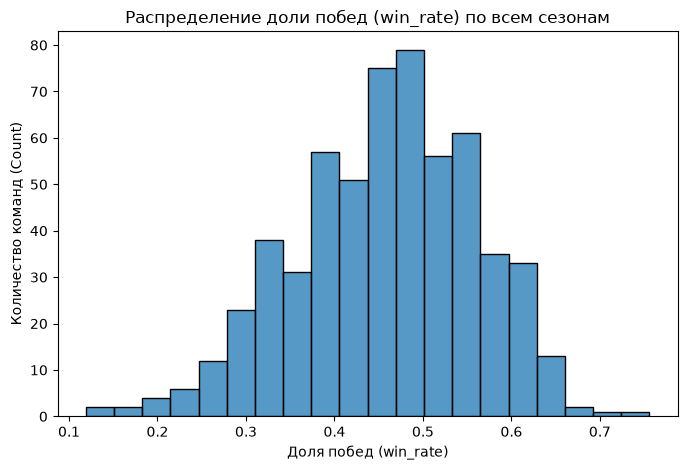

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(data=db, x="win_rate", bins=20)

plt.title('Распределение доли побед (win_rate) по всем сезонам')
plt.ylabel('Количество команд (Count)')
plt.xlabel('Доля побед (win_rate)')

**Ответ 3.1:** 

Большая часть значений `win_rate` (большинство команд) сосредоточена в интервале от 0.40 до 0.55. Из пункта 2.1 медиана составляет 0.463, а среднее значение ~0.459. Так как среднее значение близко к медиане, распределение команд симметрично. Это же видно на графике. Самое большое значение команд лежит от 0.43 до 0.5

## 3.2. Покажите изменение по годам: 8 баллов

Постройте линейный график медианы `win_rate` по годам из пункта 2.2.
        Подпишите оси. Найдите один год с заметно большей или меньшей медианой,
        чем у соседних доступных лет, и приведите числа. Отметьте в объяснении
        годы без данных.

Text(0, 0.5, 'Доля побед (win_rate)')

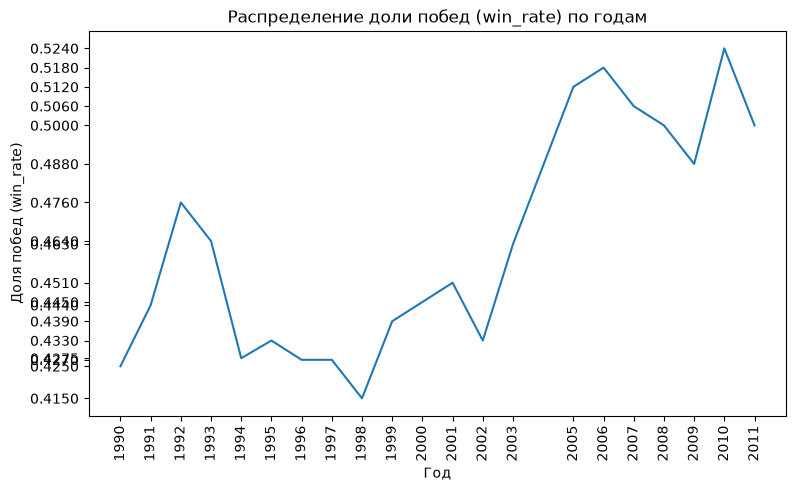

In [ ]:
plt.figure(figsize=(9, 5))
db_median = db.groupby('year', as_index=False).win_rate.median()
sns.lineplot(data=db_median, x="year", y='win_rate')

years = db_median['year'].unique()
plt.xticks(years, rotation=90)


plt.title('Распределение доли побед (win_rate) по годам')
plt.xlabel('Год')
plt.ylabel('Доля побед (win_rate)')

**Ответ 3.2:**

Год с наименьшей медианой доли побед - 1998(0.415), с наибольшей - 2010(0.524). Отсутствующий год - 2004. Года с заметным изменением относительно своих соседей: 1994 году произошел большой спад медианы доли побед относительно 1993(~0.464 =>
~0.426), в 1992 году произошел большой рост медианы доли побед относительно 1991(~0.444 => 0.476)



## 3.3. Сравните голы и долю побед: 8 баллов

Постройте диаграмму рассеяния: `goal_diff` по горизонтали,
        `win_rate` по вертикали. Опишите общую связь и приведите две конкретные
        строки для иллюстрации. Можно ли по этому графику заключить, что знак
        `goal_diff` безошибочно определяет высокую долю побед?

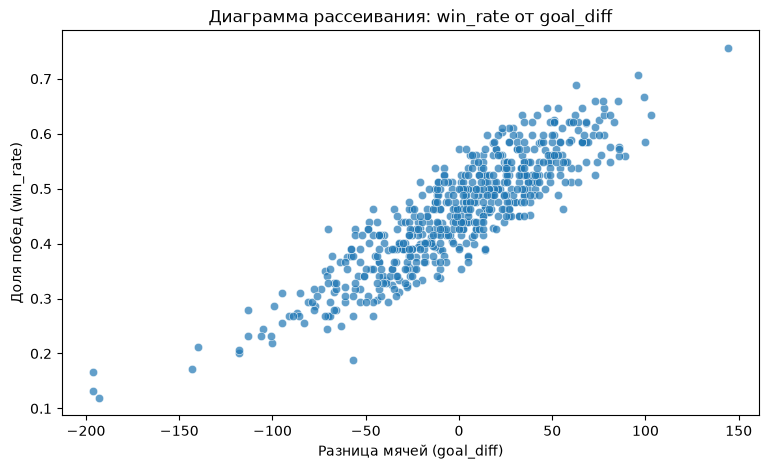

In [36]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=db, x='goal_diff', y='win_rate', alpha=0.7)

plt.title('Диаграмма рассеивания: win_rate от goal_diff')
plt.xlabel('Разница мячей (goal_diff)')
plt.ylabel('Доля побед (win_rate)')
plt.show()

In [86]:
correlation = db['goal_diff'].corr(db['win_rate'])
print(f"Коэффициент корреляции между goal_diff и win_rate: {correlation:.4f}")

Коэффициент корреляции между goal_diff и win_rate: 0.8872


**Ответ 3.3:**

Между `goal_diff` и `win_rate` положительная линейная связь. По мере увеличения параметра `goal_diff` увеличивается среднее значение параметра `win_rate`. Только по знаку `goal_diff` нельзя безошибочно определить высокую долю побед, потому что происходит слишком большой разброс данных. При одном параметре и том же `goal diff` `win_rate` может принимать несколько разных значений, которые могут даже сильно отличаться друг от друга. Коэффицент корилляции равен ~0.89, что еще раз говорит о том, что на графике преставлена линейная монотонная связь.  
Строка 1: при `goal_diff` = -50 доля побед `win_rate` равна ~0.3.  
Строка 2: при `goal_diff` = -100 доля побед `win_rate` равна ~0.22

## 3.4. Покажите историю выбранной команды: 7 баллов

Для команды из пункта 2.4 постройте график `win_rate` по годам.
        Укажите в ответе, есть ли годы без данных, и как вы показали их на графике.
        Найдите два соседних доступных сезона с заметным изменением
        и укажите значения в ответе.

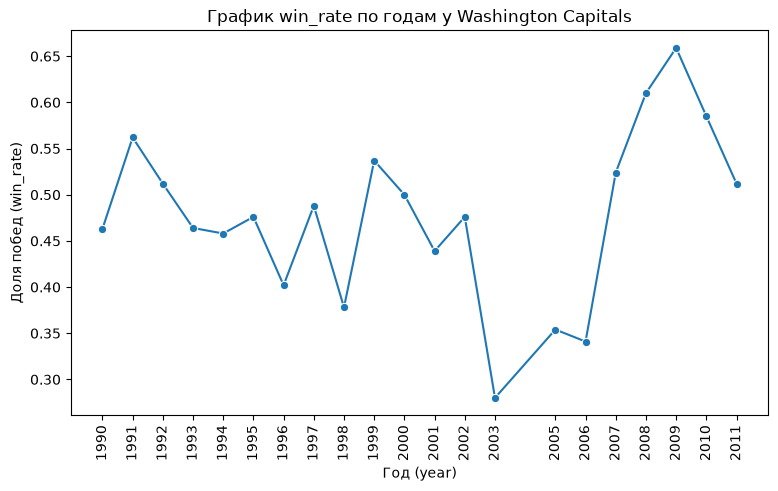

In [62]:
plt.figure(figsize=(9, 5))
db_wash = db[db.team == "Washington Capitals"]
sns.lineplot(data=db_wash, x="year", y='win_rate', marker='o')

wash_years = db_wash['year'].unique()
plt.xticks(wash_years, rotation = 90)


plt.title('График win_rate по годам у Washington Capitals')
plt.xlabel('Год (year)')
plt.ylabel('Доля побед (win_rate)')
plt.show()



**Ответ 3.4:**

Года без данных на графике есть, они не отображаются снизу на оси, так как показаны все игры, где команда участвовала. Поскольку эта команда участвовала в большинстве игр, из пункта 2.4, не играла она только в одном году - 2004 год. На графике видно 2 заметных изменения: резкий спад в 2003 году относительно 2002 года (0.476 => 0.280), резкое увеличение в 2007 году относительно 2006 года (0.341 => 0.524)

## 4.1. Проверьте последовательность лет: 5 баллов

Найдите все годы между минимальным и максимальным `year`,
        которых нет в таблице. Как отсутствие года может повлиять на линейный график?
        Сошлитесь на свой график из пункта 3.2.

In [75]:
all_years = set(range(db['year'].min(), db['year'].max() + 1))
existing_years = set(db['year'].unique())
missing_years = sorted(list(all_years - existing_years))
print(f"Все годы из таблицы: {list(all_years)}")
print(f"Минимальный год: {db['year'].min()}")
print(f"Максимальный год: {db['year'].max()}")
print(f"Пропущенные годы: {missing_years}")

Все годы из таблицы: [1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011]
Минимальный год: 1990
Максимальный год: 2011
Пропущенные годы: [2004]


**Ответ 4.1:**

В таблице присутствуют все годы, кроме 2004. На линейном графике из пункта 3.2 видно, что библиотека `seaborn` при отсутствии года проводит прямую между существующими соседями. 

## 4.2. Сравните число побед и долю: 6 баллов

Возьмите одну команду, которая есть в 1993, 1994 и 1995 годах.
        Выведите для неё `wins` и `win_rate` за эти годы.
        Какой вывод изменится, если смотреть только на число побед?
        Свяжите ответ с группировкой из пункта 2.2.

Так как у команды `Washington Capitals` отсутствуют игры только в 2004 году, выберем ее. 

In [81]:
db[db.team == "Washington Capitals"][['team', 'year', 'wins', 'win_rate']][3:6]

,team,year,wins,win_rate
91,Washington Capitals,1993,39,0.464
117,Washington Capitals,1994,22,0.458
143,Washington Capitals,1995,39,0.476


**Ответ 4.2:**

Если смотреть только на число побед, то можно сделать вывод, что команда в 1994 по сравнению с двумя соседними годами потеряла в силе, так как у нее почти в 2 раза меньше побед. Но смотря на `win_rate` становится ясно, что было сыграно гораздо меньше игр, так как `win_rate` в 1994 году упал совсем незначительно относительно 1995 года. <br>Так, из пункта 2.2 было видно, что медиана доли побед не сильно изменилась, но общее число побед упало очень сильно. 

## 4.3. Найдите собственное наблюдение: 5 баллов

Найдите ещё один интересный вам пример в таблице или на графике.
        Укажите команду, год, два значения и пункт, результат которого
        помог вам заметить пример. Как он уточняет ваш общий вывод?

In [149]:
db['ot_loss_ratio'] = db['ot_losses'] / db['losses']

db[~db['ot_losses'].isna()][['team', 'year', 'losses', 'ot_losses', 'ot_loss_ratio']].sort_values(by='ot_loss_ratio').tail(10)



,team,year,losses,ot_losses,ot_loss_ratio
464,Boston Bruins,2008,19,10.0,0.526316
516,San Jose Sharks,2009,20,11.0,0.550000
555,Calgary Flames,2011,29,16.0,0.551724
564,Los Angeles Kings,2011,27,15.0,0.555556
502,Detroit Red Wings,2009,24,14.0,0.583333
486,San Jose Sharks,2008,18,11.0,0.611111
412,Detroit Red Wings,2006,19,13.0,0.684211
563,Florida Panthers,2011,26,18.0,0.692308
402,Anaheim Ducks,2006,20,14.0,0.700000
521,Washington Capitals,2009,15,13.0,0.866667


**Ответ 4.3:**

Анализируя распределение поражений через соотношение поражений в овертайме к обычным поражениям `ot_losses / losses`, я обратил внимание на команду `Washington Capitals` в 2009 году. При общем числе основных поражений равном 15, количество поражений в овертайме (`ot_losses`) составило 13, что дает рекордное соотношение ~0.867. Этот пример помог заметить пункт 3.4, где мы исследовали историю и динамику выступлений данной команды. Данный случай уточняет общий вывод о том, что проигрыши не равны друг другу. Почти равное количество поражений в основное время и в овертаймах показывает, что команда постоянно боролась до конца и доводила матчи до ничьей, что говорит о ее высоком упорстве и конкурентоспособности

## 4.4. Сформулируйте выводы: 4 баллов

Сформулируйте два вывода из своей работы. Для каждого приведите
        номер таблицы или графика и одно число. Назовите одно ограничение данных,
        которое важно помнить при чтении результатов.

**Ответ 4.4:**

**Вывод 1:** Разница шайб `goal_diff` растет вместе с долей побед `win_rate`, что демонстрирует диаграмма рассеяния из пункта 3.3. Однако, несмотря на сильную прямую связь, по одному лишь значению `goal_diff` нельзя безошибочно определить точный `win_rate` для конкретной команды.<br>
**Вывод 2:** Оценивать эффективность команды только по абсолютному числу побед `wins` некорректно, так как длина сезонов может меняться. Например, у команды `Washington Capitals` в 1994 году (согласно сравнению из пункта 4.2) число побед упало до 22 из-за укороченного сезона, хотя её доля побед `win_rate` осталась практически на том же уровне — 0.458.

**Ограничение данных:** Важным ограничением датасета является наличие пропусков в временной шкале (например, полное отсутствие данных за 2004 год), из-за чего линейные графики соединяют соседние доступные годы напрямую, создавая визуальное сглаживание тренда и требуя осторожности при анализе роста